Name : Mohammad Ayaan Khan

USC ID : 4147952900

Email id : mkhan736@usc.edu

# DSCI 552 — Homework 3
## Time Series Classification, Part 1: Feature Creation / Extraction



## 1. Imports and configuration

In [24]:
from pathlib import Path
from zipfile import ZipFile
import urllib.request
import shutil
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 552
rng = np.random.default_rng(RANDOM_STATE)
# ARem Dataset.
DATA = "https://archive.ics.uci.edu/static/public/366/activity+recognition+system+based+on+multisensor+data+fusion+arem.zip"
WORKDIR = Path("arem_data")
WORKDIR.mkdir(exist_ok=True)

## 2. Download and extract AReM Data

In [25]:
zip = WORKDIR / "arem.zip"
dir = WORKDIR / "extracted"
dir.mkdir(parents=True, exist_ok=True)
if not zip.exists():
    print("Downloading AReM dataset...")
    urllib.request.urlretrieve(DATA, zip)
print("Dataset ZIP exists:", zip.exists())
with ZipFile(zip, "r") as zf:
    zf.extractall(dir)
print("Dataset extracted to:",dir.resolve())
#The seven activity folders
activities = {
    "bending1", "bending2", "cycling", "lying",
    "sitting", "standing", "walking"
}
dirs = [
    p for p in dir.rglob("*")
    if p.is_dir() and p.name.lower() in activities
]
act_dirs = {p.name.lower(): p for p in dirs}
print("Activity folders found:", sorted(act_dirs.keys()))
missing = activities - set(act_dirs.keys())
if missing:
    raise FileNotFoundError(
        f"Missing activity folders: {sorted(missing)}"
    )

Dataset ZIP exists: True
Dataset extracted to: /content/arem_data/extracted
Activity folders found: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


## 3. Cleaning the individual time-series files


In [26]:
## Each file that is on AReM should be parsed and cleaned into a DataFrame per instance, identifying all parsing errors, stopping in case less than 88 instances load, and marking a file with less than 480 valid rows.
import csv
import re
from pathlib import Path
import pandas as pd
COL = ["avg_rss12", "var_rss12", "avg_rss13",
    "var_rss13", "avg_rss23", "var_rss23"
]
def _canonical_column(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())
def read_arem_file(path):
    path = Path(path)
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    idx = None
    for i, line in enumerate(lines):
        normalized = _canonical_column(line)
        if all(_canonical_column(sensor) in normalized for sensor in COL):
            idx = i
            break
    if idx is None:
        raise ValueError("Could not find a header containing all six sensor columns")
    rows = []
    malf_rows = 0
    for line in lines[idx + 1:]:
        stripped = line.strip()
        if not stripped:
            continue
        # Accept comma-separated, tab-separated, or whitespace-separated data.
        toks = [t for t in re.split(r"[,\s]+", stripped) if t]
        try:
            val = [float(token) for token in toks[:7]]
        except ValueError:
            # Ignoring repeated headers, labels, and other nonnumeric lines.
            continue
        if len(val) == 7:
            rows.append(val)
        else:
            malf_rows += 1
    if not rows:
        raise ValueError("No valid numeric sensor rows found")
    df = pd.DataFrame(rows, columns=["time"] + COL)
    df = df[COL].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=COL, how="any").reset_index(drop=True)
    if df.empty:
        raise ValueError("No valid numeric sensor rows found after cleaning")
    return df
records = []
load_errors = []
for act, folder in sorted(act_dirs.items()):
    for path in sorted(p for p in folder.iterdir() if p.is_file() and not p.name.startswith(".")):
        try:
            series_df = read_arem_file(path)
            records.append({
                "activity": act,
                "file": path.name,
                "path": str(path),
                "data": series_df
            })
        except Exception as exc:
            load_errors.append({
                "activity": act,
                "file": path.name,
                "error": str(exc)
            })
print("Successfully loaded instances:", len(records))
print("Files with parsing errors:", len(load_errors))
if load_errors:
    display(pd.DataFrame(load_errors))
display(pd.Series([r["activity"] for r in records]).value_counts().sort_index())
# Stopping instead of calculating features from an incomplete dataset.
if len(records) != 88:
    raise RuntimeError(f"Expected 88 AReM instances but loaded {len(records)}.""Review the parsing-error table above before continuing.")
len_issues = [
    (r["activity"], r["file"], len(r["data"]))
    for r in records if len(r["data"]) != 480]
if len_issues:
    print("Files not containing exactly 480 valid sensor rows:")
    display(pd.DataFrame(len_issues, columns=["activity", "file", "valid_rows"]))
else:
    print("All instances contain 480 valid sensor rows.")

Successfully loaded instances: 88
Files with parsing errors: 0


,count
bending1,7
bending2,6
cycling,15
lying,15
sitting,15
standing,15
walking,15


Files not containing exactly 480 valid sensor rows:


,activity,file,valid_rows
0,sitting,dataset8.csv,479


## 4. Verifying the dataset and splitting the required train/test



In [27]:
def dataset_number(filename):
    match = re.search(r"dataset\s*[_-]?(\d+)", filename.lower())
    if match:
        return int(match.group(1))
    # Fallback: first integer in filename.
    match = re.search(r"(\d+)", filename)
    return int(match.group(1)) if match else None
def is_test_instance(activity, filename):
    n = dataset_number(filename)
    if activity in {"bending1", "bending2"}:
        return n in {1, 2}
    return n in {1, 2, 3}
for r in records:
    r["dataset_number"] = dataset_number(r["file"])
    r["split"] = "test" if is_test_instance(r["activity"], r["file"]) else "train"
split_summ = pd.crosstab(
    pd.Series([r["activity"] for r in records], name="activity"),
    pd.Series([r["split"] for r in records], name="split")
)
display(split_summ)
print("Total instances:", len(records))
print("Train instances:", sum(r["split"] == "train" for r in records))
print("Test instances:", sum(r["split"] == "test" for r in records))
# 88 instances total.
if len(records) != 88:
    print("WARNING: The assignment describes 88 instances. Check the archive layout, "
          "file parsing, and any skipped files before relying on results.")

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


Total instances: 88
Train instances: 69
Test instances: 19


## 5. Extracting seven time-domain features from each of six series


In [28]:
#Extract seven time-domain features (min, max, mean, median, std, Q1, Q3) for every instance across the six series of sensors to obtain a numerical feature matrix consisting of 42 columns, along with its relevant metadata.
feat = ["min", "max", "mean", "median", "std", "q1", "q3"]
def extract_features(instance):
    row = {
        "activity": instance["activity"],
        "file": instance["file"],
        "dataset_number": instance["dataset_number"],
        "split": instance["split"]
    }
    for sensor in COL:
        val = instance["data"][sensor].to_numpy(dtype=float)
        pref = sensor
        row[f"{pref}_min"] = np.min(val)
        row[f"{pref}_max"] = np.max(val)
        row[f"{pref}_mean"] = np.mean(val)
        row[f"{pref}_median"] = np.median(val)
        row[f"{pref}_std"] = np.std(val, ddof=1)
        row[f"{pref}_q1"] = np.quantile(val, 0.25)
        row[f"{pref}_q3"] = np.quantile(val, 0.75)
    return row
feature_df = pd.DataFrame([extract_features(r) for r in records])
feature_cols = [
    f"{sensor}_{feature}"
    for sensor in COL
    for feature in feat
]
display(feature_df.head())
print("Feature matrix shape (including metadata):", feature_df.shape)
print("Number of numerical features:", len(feature_cols))

,activity,file,dataset_number,split,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_q1,...,avg_rss23_std,avg_rss23_q1,avg_rss23_q3,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_q1,var_rss23_q3
0,bending1,dataset1.csv,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,dataset2.csv,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,dataset3.csv,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,dataset4.csv,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,dataset5.csv,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Feature matrix shape (including metadata): (88, 46)
Number of numerical features: 42


In [29]:
# Rename the 42 feature columns according to required rules and re-index the table from 1.
stat_names = {
    "min": "min", "max": "max", "mean": "mean", "median": "median",
    "std": "std", "q1": "1st_quart", "q3": "3rd_quart"
}
map = {
    f"{sensor}_{stat}": f"{stat_names[stat]}{i}"
    for i, sensor in enumerate(COL, start=1)
    for stat in feat
}
table = feature_df.rename(columns=map).copy()
table.index = pd.RangeIndex(1, len(table) + 1, name="Instance")
display(table.head())
print("Assignment-style feature table shape:", table.shape)

,activity,file,dataset_number,split,min1,max1,mean1,median1,std1,1st_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,dataset1.csv,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,dataset2.csv,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,dataset3.csv,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,dataset4.csv,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,dataset5.csv,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Assignment-style feature table shape: (88, 46)


Using the 88 cases as our observational units. For each feature, we calculate the standard deviation of values across cases. To form a 90% CI, we will use percentiles and perform a bootstrap sampling of cases with replacement and then compute the 5th and 95th percentiles of the distribution of bootstrap sampling estimates of the standard deviation.

This calculated interval gives a measure of the uncertainty in the standard deviation computed across all instances, but it does not yield an interval pertaining to a particular value of a time series.

In [30]:
def bootstrap_sd_ci(values, n_boot=5000, confidence=0.90, seed=552):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan, np.nan, np.nan
    loc_rng = np.random.default_rng(seed)
    n = len(values)
    boot_sds = np.empty(n_boot)
    for b in range(n_boot):
        sample = loc_rng.choice(values, size=n, replace=True)
        boot_sds[b] = np.std(sample, ddof=1)
    alp = 1 - confidence
    return (
        np.std(values, ddof=1),
        np.quantile(boot_sds, alp / 2),
        np.quantile(boot_sds, 1 - alp / 2)
    )
ci_rows = []
for j, col in enumerate(feature_cols):
    estimate, low, high = bootstrap_sd_ci(
        feature_df[col].to_numpy(), n_boot=5000, confidence=0.90,
        seed=RANDOM_STATE + j
    )
    ci_rows.append({
        "feature": col,
        "estimated_sd": estimate,
        "90% CI lower": low,
        "90% CI upper": high
    })
sd_ci_table = pd.DataFrame(ci_rows).sort_values("feature").reset_index(drop=True)
display(sd_ci_table.round(4))

,feature,estimated_sd,90% CI lower,90% CI upper
0,avg_rss12_max,4.3944,3.3607,5.2954
1,avg_rss12_mean,5.3357,4.6930,5.9045
2,avg_rss12_median,5.4401,4.7818,5.9909
3,avg_rss12_min,9.5700,8.2629,10.7754
4,avg_rss12_q1,6.1536,5.5620,6.6487
5,avg_rss12_q3,5.1389,4.3463,5.8195
6,avg_rss12_std,1.7722,1.5788,1.9615
7,avg_rss13_max,4.8751,4.1773,5.4748
8,avg_rss13_mean,4.0084,3.4085,4.4781
9,avg_rss13_median,4.0364,3.4579,4.5436


### Visualizing the estimated standard deviations

High standard deviations indicate features that vary a lot across instances, but variation is not enough to ensure good classification results.

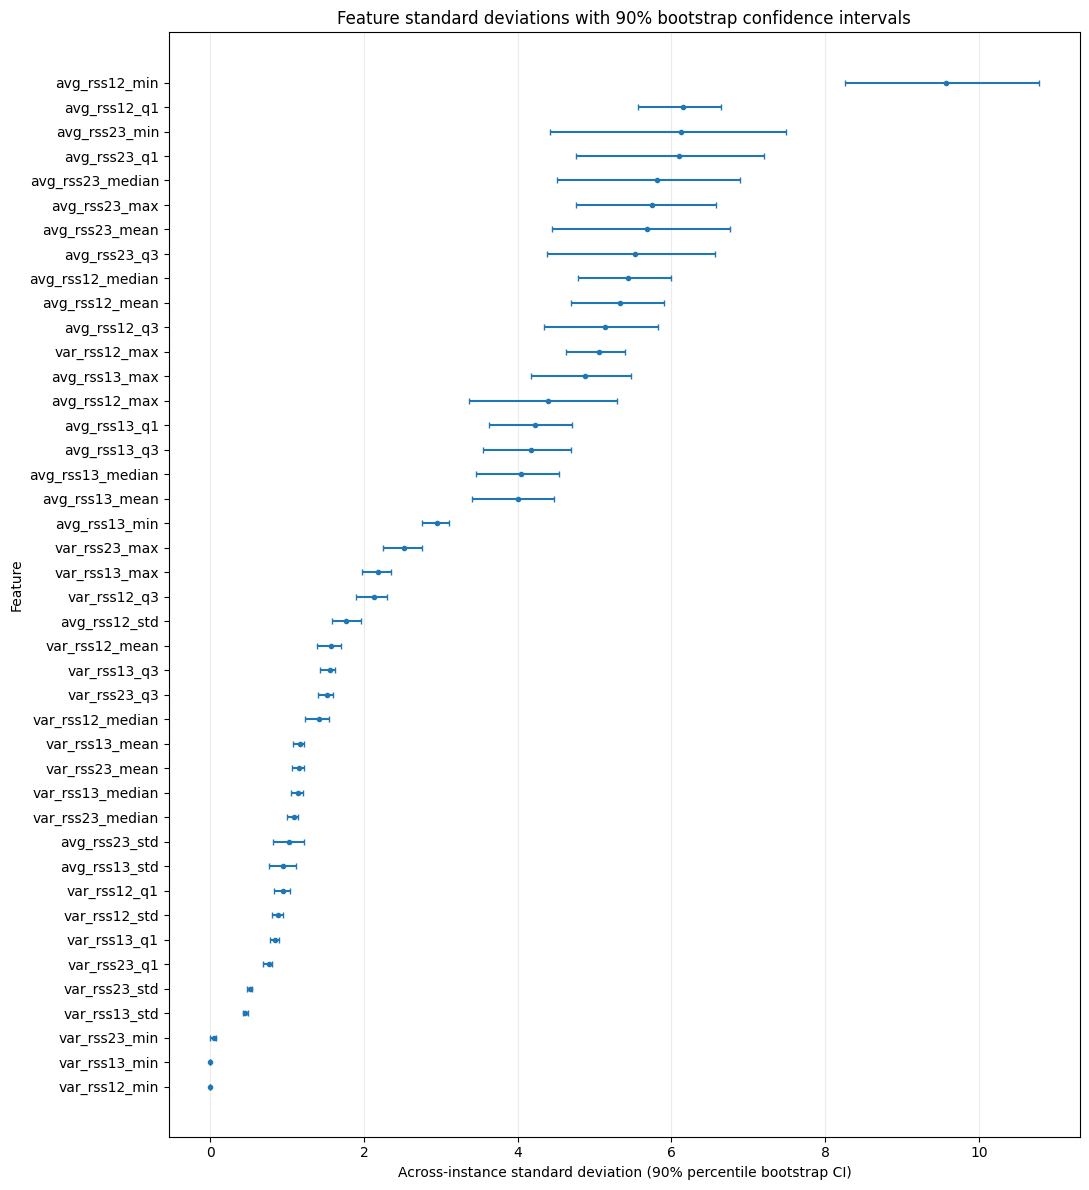

In [22]:
plot_df = sd_ci_table.sort_values("estimated_sd", ascending=True).reset_index(drop=True)
lower_err = plot_df["estimated_sd"] - plot_df["90% CI lower"]
upper_err = plot_df["90% CI upper"] - plot_df["estimated_sd"]
fig, ax = plt.subplots(figsize=(11, 12))
ax.errorbar(
    plot_df["estimated_sd"],
    plot_df["feature"],
    xerr=[lower_err, upper_err],
    fmt="o",
    capsize=2,
    markersize=3
)
ax.set_title("Feature standard deviations with 90% bootstrap confidence intervals")
ax.set_xlabel("Across-instance standard deviation (90% percentile bootstrap CI)")
ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Selecting three important time-domain features

In our case, what is required is not choosing three particular columns that represent individual sensors, but rather opting for three general types of time-domain statistical measures. Our selection includes the following measures: minimum value, mean and maximum value. While minimum and maximum represent extremities of a signal, the mean value is indicative of the average signal level. These measures provide a means of differentiating between movements with higher fluctuations and more static positions. The median and quartiles represent central tendency as well, but they may partly overlap with the mean measure.

In order to receive supporting evidence without actually using the test set for the purpose of selecting the features, the next section is intended to rank features based exclusively on ANOVA F-statistics that are calculated for the training dataset only. The final choice of minimum, mean, and maximum remains a judgment-based choice permitted by the assignment

Median ANOVA F-statistic across the six sensor series (training set only):


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 7 21] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,median_F
stat,
mean,307.442
q3,297.070
median,252.826
q1,135.156
std,71.918
max,32.327
min,16.841


Selected statistic types: ['min', 'mean', 'max']


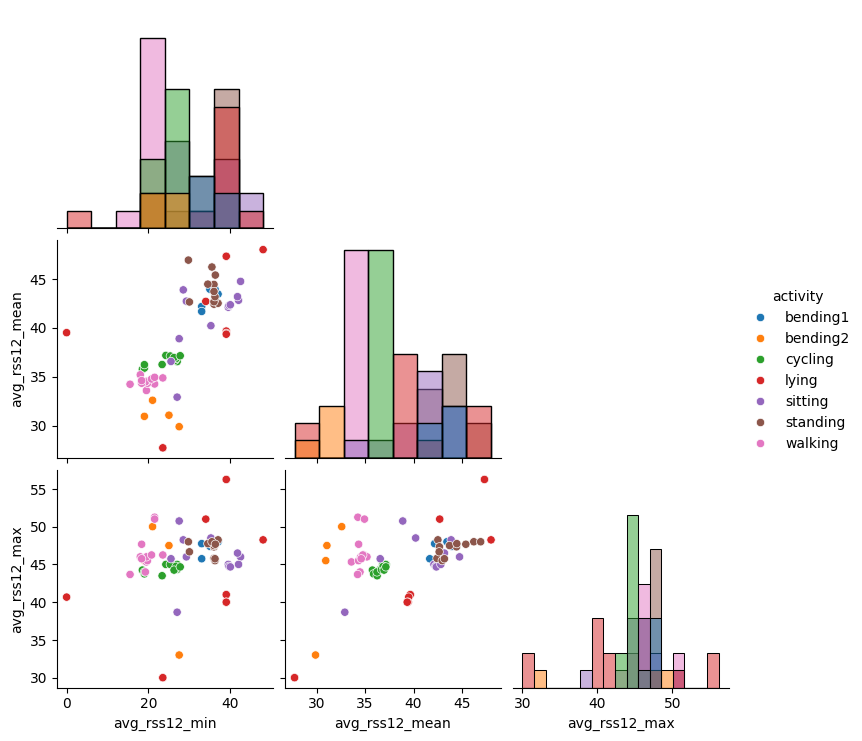

In [17]:
from sklearn.feature_selection import f_classif
train_df = feature_df.loc[feature_df["split"] == "train"].copy()
F, p_values = f_classif(train_df[feature_cols], train_df["activity"])
f_df = pd.DataFrame({"F": F, "p_value": p_values}, index=feature_cols)
f_df["stat"] = [c.rsplit("_", 1)[1] for c in feature_cols]
stat_ranking = f_df.groupby("stat")["F"].median().sort_values(ascending=False)
print("Median ANOVA F-statistic across the six sensor series (training set only):")
display(stat_ranking.to_frame("median_F").round(3))
selected_stats = ["min", "mean", "max"]
print("Selected statistic types:", selected_stats)
# Illustrative plot for sensor series 1 using the three selected statistics.
example_features = ["avg_rss12_min", "avg_rss12_mean", "avg_rss12_max"]
sns.pairplot(
    feature_df.loc[feature_df["split"] == "train"],
    vars=example_features,
    hue="activity",
    diag_kind="hist",
    corner=True)
plt.show()

## 8. Export the extracted feature table and confidence intervals

The generated files can be reused for the later classification portion of the assignment.

In [23]:
output_dir = Path("arem_outputs")
output_dir.mkdir(exist_ok=True)
feature_df.to_csv(output_dir / "arem_features_42.csv", index=False)
sd_ci_table.to_csv(output_dir / "feature_sd_bootstrap_ci_90.csv", index=False)
print("Saved:")
print(output_dir / "arem_features_42.csv")
print(output_dir / "feature_sd_bootstrap_ci_90.csv")

Saved:
arem_outputs/arem_features_42.csv
arem_outputs/feature_sd_bootstrap_ci_90.csv


## 9.1(c)

### (i) Common time-domain features

Several time-domain characteristics are utilized, such as minimum, maximum, range, mean, median, variance, standard deviation, RMS, quantiles (quartiles, IQR), and the skewness and kurtosis of a sample, as well as the zero-crossing rate and slope/trend. However, in this case, only a few of them are required in this assignment, i.e., the minimum, maximum, mean, median, standard deviation, first quartile, and third quartile.

### (ii) Extracted feature table

The program generates one row for each activity instance along with 42 numerical characteristics which are composed of 7 statistics for the 6 sensor series. The activity, the file, and the split columns constitute metadata and they are not included in the 42-feature vector.
### (iii) Standard deviations and bootstrap intervals
The sample standard deviations for every characteristic are shown in the table sd_ci_table, along with the values of the associated  percentile 90% bootstrap confidence interval. The numbers listed here were taken from the output generated from this notebook after downloading the data set and making sure its processing is correct.

Because all the instances bring their variance series down to zero at some point, the minimum of two variance series (var_rss12_min, var_rss13_min) with a standard deviation of 0, along with 90% CI of [0,0]. The value of var_rss23_min is almost the same because of this.

### (iv) Three selected features

The three chosen statistics of time-domain are **minimum, mean and maximum**. Minimum and maximum demonstrate extremes of the signal while the mean indicates normal signal level. The training based ANOVA ranking gives evidence about class separation without using the testing labels in selecting the features.

Minimum has good significance in avg_rss series, however, it is (almost) always 0 in the var_rss series, meaning that in case of these series the only relevant statistics could be mean and max.

**Data note:** The original dataset has duplicate instances. For instance, cycling/dataset1 = cycling/dataset15, lying/dataset1 ≈ lying/dataset10 = lying/dataset15, lying/dataset3 = lying/dataset11. The pre-defined split is maintained; however, since 3 test instances have duplicates in the train dataset, test accuracy could be overestimated at classification stage.

## Question 2 — ISLR Exercise 3.7.4: Linear versus cubic regression

**Problem setup:** In this case, we have 100 observations of predictor X and quantitative response variable Y. We fit both linear regression and cubic regression models to the data.



### (a) Training RSS when the true relationship is linear

**Answer:** We know that the training RSS from the cubic regression will always be less than or equal to that of the linear regression.

The cubic model includes the linear model as a specific case by putting beta_2=beta_3=0, we arrive at the linear model. Since the least squares method chooses the coefficients in such a way that training RSS is minimized, compared to the cubic model, the linear model does not offer any additional flexibility and cannot produce a lower minimum RSS value than the cubic model for identical data samples.

This result follows from the nested models, even when the true relationship is linear.

### (b) Test RSS when the true relationship is linear

**Answer:** Typically, we anticipate that linear regression will be more efficient in terms of test RSS, or at least this is what we observe most of the time, though this is not entirely true in each case.

Because the actual relationship is linear, the linear model is able to correctly capture the mean relationship. The inclusion of extra X^2 and X^3 in the cubic model adds unnecessary complexity, which can lead to overfitting of the random variations in the training set and increasing the variance that may negatively impact prediction quality when applied to test observations. Thus, under normal circumstances, the linear model is expected to perform better.

### (c) Training RSS when the true relationship is nonlinear

**Answer:** Again, cubic regression training RSS will be less than or equal to linear regression training RSS.

The cubic model includes the linear model as a special case, meaning that its least-squares training RSS cannot be greater than the least-square training RSS of the linear model.

If cubic terms capture nonlinear structure, training RSS may be further decreased. The inequality itself does not depend on whether the true relationship is nonlinear.

### (d) Test RSS when the true relationship is nonlinear

**Answer:** We cannot conclude which model will result in lower test RSS.

However, if the true nonlinear relationship can be represented well by a cubic polynomial, the cubic model may provide a better approximation. Nonetheless, the actual relationship might take a different form, owing to which the cubic model will either increase the variance unnecessarily or fail to fit the data well. The measure of test RSS will depend on the actual nature of the non-linear relationship and the level of noise and distribution of predictor values involved in the equation.